In [1]:
# 01a — Exploratory Data Analysis: Pakistan (PERI_DEP)

Dataset: `pakistan_peridep_raw.csv` — 14,008 women, Lahore/Gujranwala, Pakistan.

Goal: understand the data before touching it — shape, missingness, class balance,
distributions, and a first look at how the PHQ-9 items relate to the label
(formal leakage proof comes in `02_leakage_audit.ipynb`).

We do not modify or save any files here — pure exploration.

SyntaxError: invalid character '—' (U+2014) (391443375.py, line 3)

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

SEED = config["seed"]
RAW_DIR = os.path.join(PROJECT_ROOT, config["paths"]["raw_dir"])

raw_path = os.path.join(RAW_DIR, config["raw_files"]["pakistan_raw"])
print("Loading:", raw_path)

df = pd.read_csv(raw_path)
print("Shape:", df.shape)

Loading: C:\maternal-mental-health-risk\data/raw\pakistan_peridep_raw.csv
Shape: (14008, 27)


In [3]:
df.head()

,Age,Gestational Age,Number of sons,Number of daughters,Total Number of Children,Gravida,Female Education,Husband Education,Working Status,Physical Health,Previous Miscarriage,Sufficient Money for Basic Needs,Current Appereance Acceptance,Family System,Male Gender Preference,Relationship with Mother in-law,Little interest or pleasure in doing things,"Feeling down, depressed, or hopeless",Trouble falling or staying sleep or sleeping too much,Feeling tired or having little energy,Poor appetite or overeating,Feeling badabout yourself that you are failure or have let yourself or your family down,"Trouble concentrating on things, such as reading the newspaper or watching television",Moving or speaking so slowly that other people could have Noticed.,"Thoughts that you would be better off dead, or of hurting yourself",Scalling,Labelling
0,25.0,26,0,0,0,Primigravida,Graduation,Graduation,Housewife,Healthy,No,Yes,Yes,Nuclear,Yes,Moderate,1,3,1,1,2,2,3,2.0,1.0,16,Depressed
1,28.0,35,0,1,1,Multigravida,Intermediate,Matric,Working Lady,Healthy,No,Yes,Yes,Joint,Yes,Good,1,2,3,0,3,1,2,0.0,1.0,13,Depressed
2,26.0,28,0,0,0,Primigravida,Graduation,Graduation,Housewife,Healthy,No,Yes,Yes,Joint,Yes,Poor,1,1,3,2,0,3,3,0.0,0.0,13,Depressed
3,25.0,28,0,1,1,Multigravida,Graduation,Graduation,Housewife,Healthy,No,Yes,Yes,Joint,Yes,Poor,1,0,3,3,3,1,3,3.0,0.0,17,Depressed
4,24.0,39,0,0,0,Primigravida,Graduation,Graduation,Housewife,Healthy,No,Yes,Yes,Joint,Yes,Good,2,1,0,1,1,0,0,0.0,0.0,5,Not


In [4]:
for i, col in enumerate(df.columns):
    flag = "  <- has leading/trailing whitespace" if col != col.strip() else ""
    print(f"{i:2d}. {repr(col)}{flag}")

 0. 'Age'
 1. 'Gestational Age'
 2. 'Number of sons '  <- has leading/trailing whitespace
 3. 'Number of daughters'
 4. 'Total Number of Children'
 5. 'Gravida'
 6. 'Female Education'
 7. 'Husband Education'
 8. 'Working Status'
 9. 'Physical Health '  <- has leading/trailing whitespace
10. 'Previous Miscarriage'
11. 'Sufficient Money for Basic Needs'
12. 'Current Appereance Acceptance'
13. 'Family System'
14. 'Male Gender Preference'
15. 'Relationship with Mother in-law'
16. 'Little interest or pleasure in doing things'
17. 'Feeling down, depressed, or hopeless'
18. 'Trouble falling or staying sleep or sleeping too much'
19. 'Feeling tired or having little energy'
20. 'Poor appetite or overeating'
21. 'Feeling badabout yourself that you are failure or have let yourself or your family down'
22. 'Trouble concentrating on things, such as reading the newspaper or watching television '  <- has leading/trailing whitespace
23. 'Moving or speaking so slowly that other people could have Notice

In [5]:
df.dtypes

Age                                                                                        float64
Gestational Age                                                                              int64
Number of sons                                                                               int64
Number of daughters                                                                          int64
Total Number of Children                                                                     int64
Gravida                                                                                        str
Female Education                                                                               str
Husband Education                                                                              str
Working Status                                                                                 str
Physical Health                                                                                str
Previous M

In [6]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if missing.empty:
    print("No missing values found.")
else:
    print(missing)
    print(f"\nTotal missing cells: {df.isna().sum().sum()} out of {df.shape[0]*df.shape[1]} "
          f"({100*df.isna().sum().sum()/(df.shape[0]*df.shape[1]):.4f}%)")

Moving or speaking so slowly that other people could have Noticed.     6
Thoughts that you would be better off dead, or of hurting yourself     4
Sufficient Money for Basic Needs                                       4
Age                                                                    2
Male Gender Preference                                                 2
dtype: int64

Total missing cells: 18 out of 378216 (0.0048%)


Labelling
Depressed    9078
Not          4930
Name: count, dtype: int64

Labelling
Depressed    64.81
Not          35.19
Name: proportion, dtype: float64 %


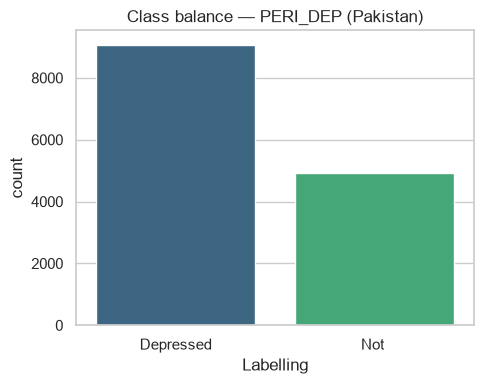

In [7]:
print(df["Labelling"].value_counts())
print()
print(df["Labelling"].value_counts(normalize=True).round(4) * 100, "%")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Labelling", hue="Labelling", palette="viridis", legend=False, ax=ax)
ax.set_title("Class balance — PERI_DEP (Pakistan)")
plt.tight_layout()
plt.show()

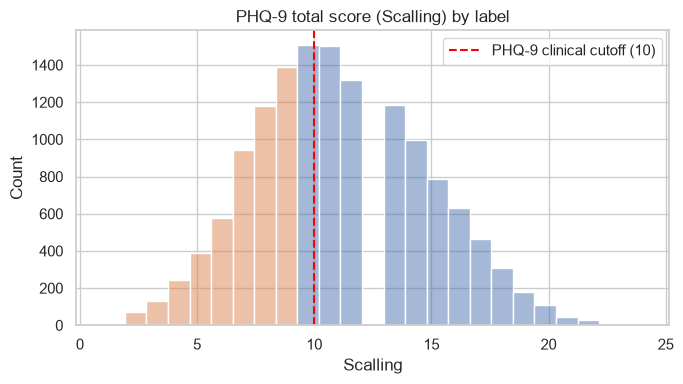

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x="Scalling", hue="Labelling", bins=25, kde=False, ax=ax)
ax.axvline(10, color="red", linestyle="--", label="PHQ-9 clinical cutoff (10)")
ax.set_title("PHQ-9 total score (Scalling) by label")
ax.legend()
plt.tight_layout()
plt.show()

# Note the clean separation at 10 — this is expected since Labelling is a direct
# threshold of Scalling. We prove and handle this formally in notebook 02.

In [9]:
numeric_cols = ["Age", "Gestational Age", "Number of sons ", "Number of daughters",
                "Total Number of Children", "Scalling"]
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,14006.0,28.050835,5.119757,3.0,25.0,28.0,31.0,46.0
Gestational Age,14008.0,31.056539,3.837895,26.0,28.0,30.0,34.0,41.0
Number of sons,14008.0,1.063107,1.125971,0.0,0.0,1.0,2.0,6.0
Number of daughters,14008.0,1.091733,1.156527,0.0,0.0,1.0,2.0,6.0
Total Number of Children,14008.0,2.155982,1.470060,0.0,1.0,2.0,3.0,7.0
Scalling,14008.0,11.067390,3.716620,1.0,8.0,11.0,14.0,24.0


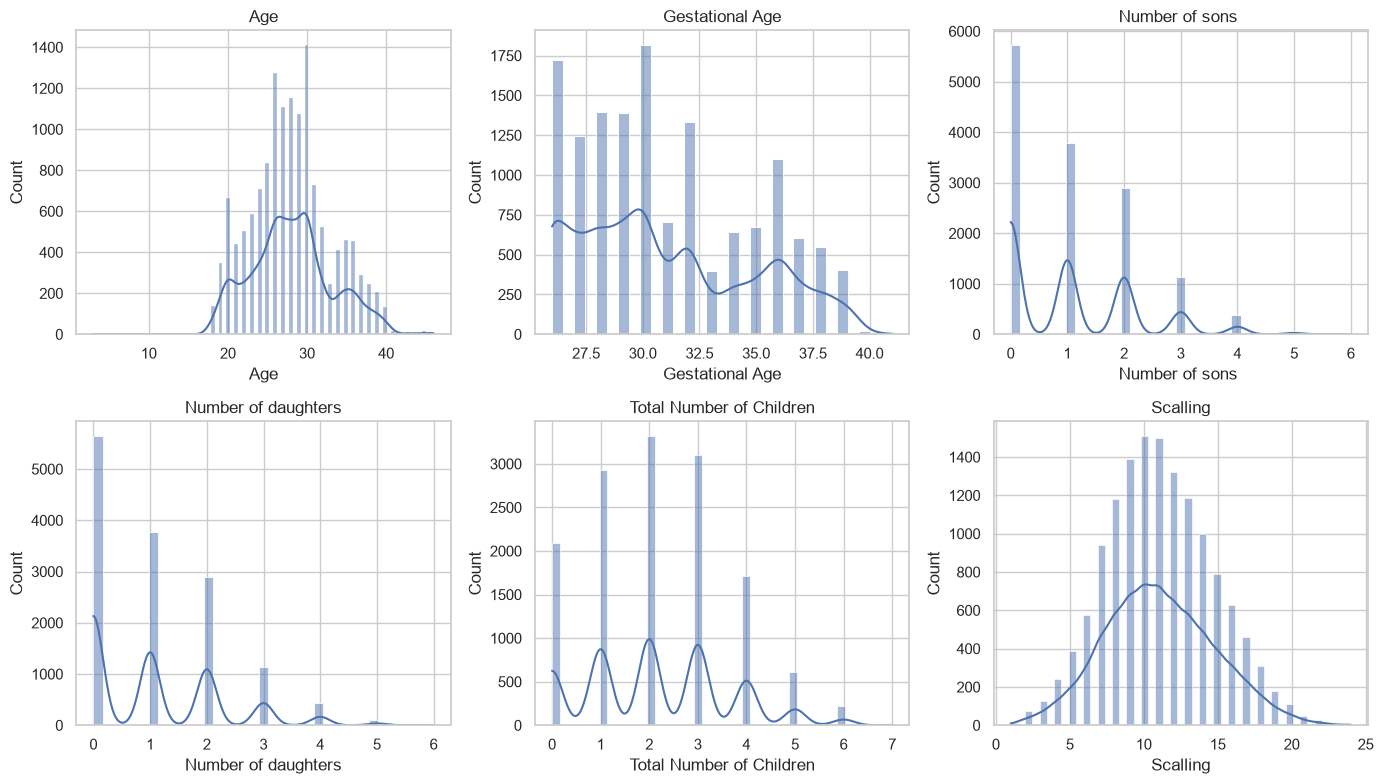

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [11]:
sdoh_cols = ["Female Education", "Husband Education", "Working Status", "Physical Health ",
             "Previous Miscarriage", "Sufficient Money for Basic Needs",
             "Current Appereance Acceptance", "Family System", "Male Gender Preference",
             "Relationship with Mother in-law", "Gravida"]

for col in sdoh_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- Female Education ---
Female Education
Matric          3939
Intermediate    3124
Uneducated      2462
Primary         2094
Middle          1462
Graduation       829
Middle            64
Uneducated        34
Name: count, dtype: int64

--- Husband Education ---
Husband Education
Matric          3656
Uneducated      3166
Intermediate    2557
Primary         2541
Middle          1334
Graduation       662
Middle            56
Uneducated        36
Name: count, dtype: int64

--- Working Status ---
Working Status
Housewife        10368
Working Lady      1976
Working Lady      1664
Name: count, dtype: int64

--- Physical Health  ---
Physical Health 
Healthy    13868
Disable      140
Name: count, dtype: int64

--- Previous Miscarriage ---
Previous Miscarriage
No      8525
Yes     3877
No       972
Yes      634
Name: count, dtype: int64

--- Sufficient Money for Basic Needs ---
Sufficient Money for Basic Needs
No      6165
Yes     5999
No       975
Yes      865
NaN        4
Name: count, dtype:

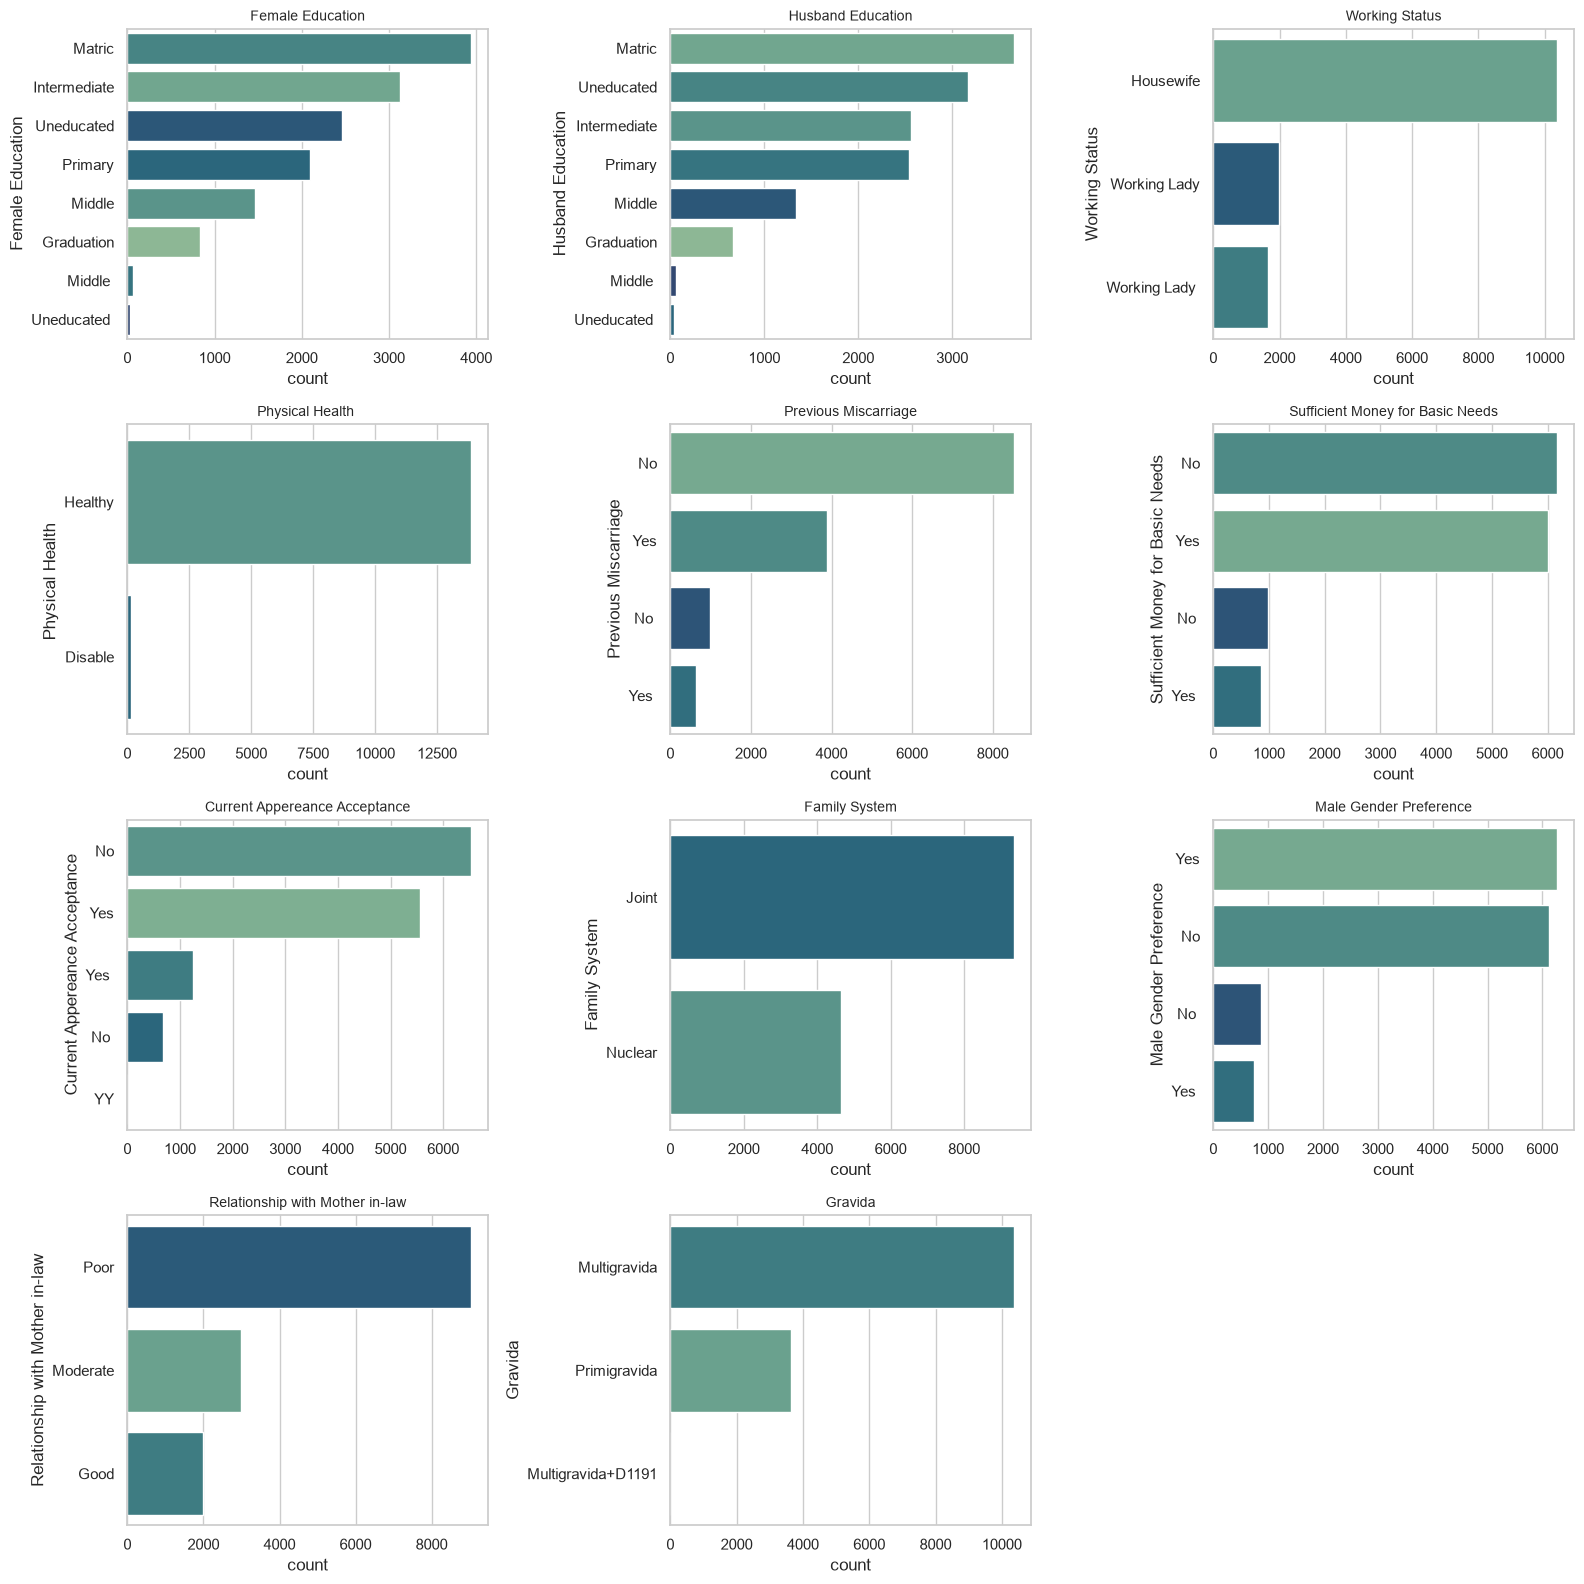

In [12]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flat, sdoh_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, hue=col, palette="crest", legend=False, ax=ax)
    ax.set_title(col, fontsize=10)
for ax in axes.flat[len(sdoh_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [13]:
for col in sdoh_cols:
    ct = pd.crosstab(df[col], df["Labelling"], normalize="index") * 100
    print(f"--- % Depressed within each level of {col} ---")
    print(ct.round(1))
    print()

--- % Depressed within each level of Female Education ---
Labelling         Depressed  Not 
Female Education                 
Graduation             58.4  41.6
Intermediate           65.0  35.0
Matric                 66.5  33.5
Middle                 61.7  38.3
Middle                 62.5  37.5
Primary                63.8  36.2
Uneducated             66.9  33.1
Uneducated             58.8  41.2

--- % Depressed within each level of Husband Education ---
Labelling          Depressed  Not 
Husband Education                 
Graduation              61.6  38.4
Intermediate            62.5  37.5
Matric                  66.6  33.4
Middle                  65.7  34.3
Middle                  64.3  35.7
Primary                 65.5  34.5
Uneducated              64.4  35.6
Uneducated              61.1  38.9

--- % Depressed within each level of Working Status ---
Labelling       Depressed  Not 
Working Status                 
Housewife            65.5  34.5
Working Lady         62.1  37.9
Working

PHQ-9 item + score columns detected:
 - 'Little interest or pleasure in doing things'
 - 'Feeling down, depressed, or hopeless'
 - 'Trouble falling or staying sleep or sleeping too much'
 - 'Feeling tired or having little energy'
 - 'Poor appetite or overeating'
 - 'Feeling badabout yourself that you are failure or have let yourself or your family down'
 - 'Trouble concentrating on things, such as reading the newspaper or watching television '
 - 'Moving or speaking so slowly that other people could have Noticed. '
 - 'Thoughts that you would be better off dead, or of hurting yourself'


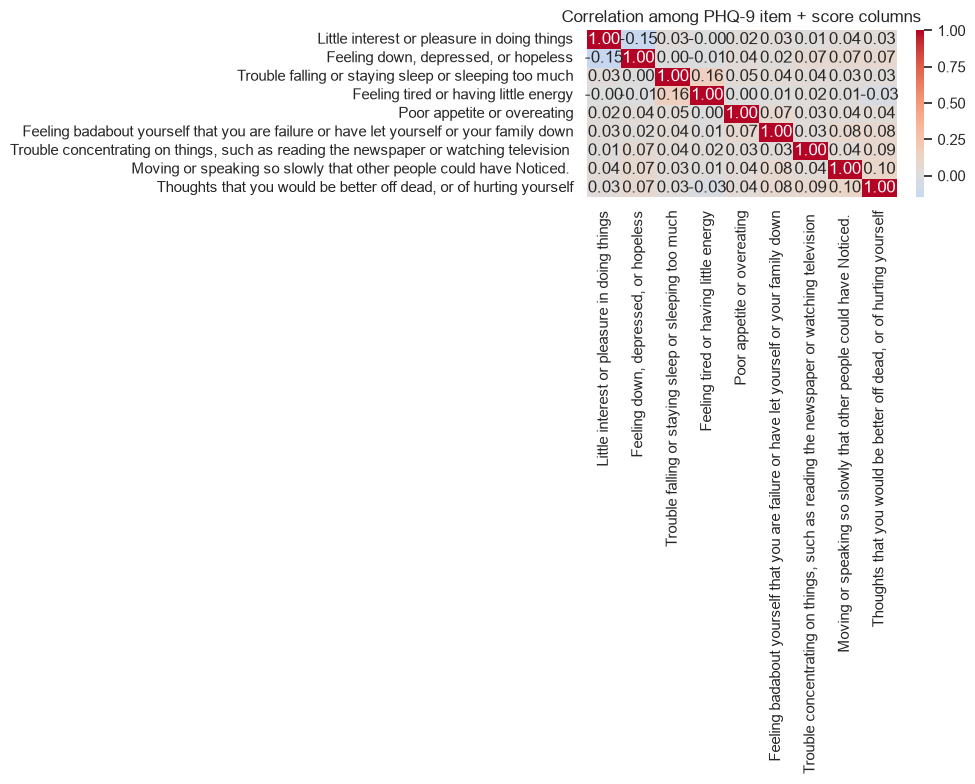

In [14]:
phq_item_cols = [c for c in df.columns if c not in
    ['Age','Gestational Age','Number of sons ','Number of daughters','Total Number of Children',
     'Gravida','Female Education','Husband Education','Working Status','Physical Health ',
     'Previous Miscarriage','Sufficient Money for Basic Needs','Current Appereance Acceptance',
     'Family System','Male Gender Preference','Relationship with Mother in-law',
     'Scalling','Labelling']]
print("PHQ-9 item + score columns detected:")
for c in phq_item_cols:
    print(" -", repr(c))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df[phq_item_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation among PHQ-9 item + score columns")
plt.tight_layout()
plt.show()